## Retail Sales Data — Exploratory Data Analysis (EDA)

## Introduction
This project analyzes retail sales data to identify sales trends, product performance, customer segments, and regional profitability using Python.

## Project Overview
Exploratory Data Analysis (EDA) is the process of examining a dataset before making conclusions or building predictive models. It helps understand the structure of the data, identify missing or unusual values, summarize important variables, and discover patterns through tables and visualizations.

This project uses the Sample Superstore retail dataset. It includes order dates, customer segments, product details, sales, quantity, discount, profit, and regional information. The analysis focuses on understanding when sales occur, which products and categories contribute most to sales, how customer segments are represented, and how numerical variables relate to one another.

## Tools used
Pandas is used to load, clean, group, and summarize the data. Matplotlib and Seaborn are used to create charts that make patterns easier to interpret.

## Load  Dataset

Loading the dataset is the first step in the analysis. A CSV file stores tabular data as rows and columns and can be read into a Pandas DataFrame for convenient processing. After loading, the first few rows should be displayed to confirm that the file was read correctly and that the column names and values look reasonable.

The file path used in the code assumes that Sample - Superstore.csv is in the same folder as this notebook. If the dataset is stored elsewhere, update the path accordingly.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")

# Display the first five rows
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## Perform Initial Inspection

Initial inspection helps establish the size and structure of the dataset before analysis. The number of rows and columns indicates how many records and attributes are available. Column names show which business details can be studied, while data types indicate whether values are stored as numbers, text, or dates.

Checking missing values is important because blank fields can affect calculations and visualizations. The missing-value count helps identify whether cleaning is needed. A zero count means no missing values were detected in those columns, but it does not by itself guarantee that every value is valid or correctly formatted.

In [4]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data types:
Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

Missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name   

## Descriptive Statistical Analysis

Descriptive statistics summarize the main characteristics of numerical data. The mean is the arithmetic average, the median is the middle value after sorting, the mode is the most frequently occurring value, and the standard deviation describes how spread out values are around the mean.

These measures provide a quick overview of sales, quantity, discount, and profit. A large difference between the mean and median can suggest that a variable is skewed by unusually high or low values. Statistics should be interpreted in the context of each column; for example, the mean of a row identifier or postal code is generally not a meaningful business measure.

In [5]:
# Select numerical columns
numeric_cols = df.select_dtypes(include="number")

# Calculate descriptive statistics
print("Mean:\n", numeric_cols.mean())
print("\nMedian:\n", numeric_cols.median())
print("\nMode:\n", numeric_cols.mode().iloc[0])
print("\nStandard Deviation:\n", numeric_cols.std())


Mean:
 Row ID          4997.500000
Postal Code    55190.379428
Sales            229.858001
Quantity           3.789574
Discount           0.156203
Profit            28.656896
dtype: float64

Median:
 Row ID          4997.5000
Postal Code    56430.5000
Sales             54.4900
Quantity           3.0000
Discount           0.2000
Profit             8.6665
dtype: float64

Mode:
 Row ID             1.00
Postal Code    10035.00
Sales             12.96
Quantity           3.00
Discount           0.00
Profit             0.00
Name: 0, dtype: float64

Standard Deviation:
 Row ID          2885.163629
Postal Code    32063.693350
Sales            623.245101
Quantity           2.225110
Discount           0.206452
Profit           234.260108
dtype: float64


## Time Series Analysis

Time series analysis examines observations in chronological order. In retail, dates make it possible to study how sales change over time and whether certain periods consistently perform better than others. Before resampling, the order-date column must be converted from text into a proper datetime format so Pandas can group records by month or quarter.

Aggregating sales by time period reduces daily detail into a trend that is easier to compare. These charts can support planning, but a trend alone does not explain why sales changed; promotions, holidays, product availability, and other factors may also contribute.

In [6]:
# Convert order date to datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

# Check the date range
print("Start date:", df["Order Date"].min())
print("End date:", df["Order Date"].max())

# Check total sales
print("Total sales:", df["Sales"].sum())

Start date: 2014-01-03 00:00:00
End date: 2017-12-30 00:00:00
Total sales: 2297200.8603


## Monthly Sales Trend Analysis

Monthly aggregation combines the sales values for all orders within each calendar month. A line chart is suitable for this task because it emphasizes changes across a continuous sequence of dates. Peaks indicate months with higher total sales, while troughs indicate lower-sales months.

Monthly trends can help a retailer plan stock levels, staffing, and promotional timing. When comparing months, remember that totals can be affected by the number of orders, order size, holidays, and seasonal demand. The chart describes historical performance and should not be treated as a guaranteed forecast.

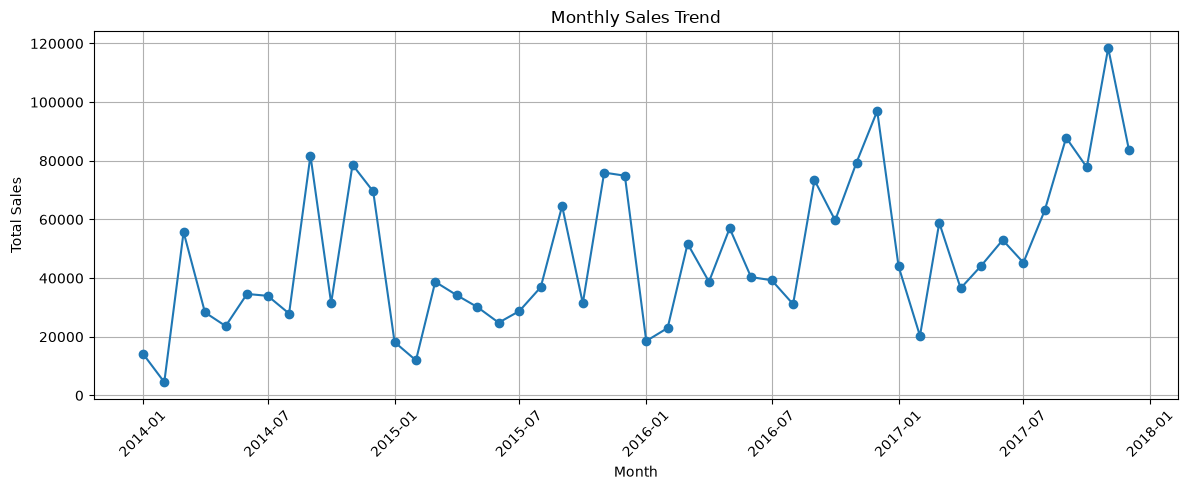

In [7]:
monthly_sales = (
    df.dropna(subset=["Order Date"])
      .set_index("Order Date")["Sales"]
      .resample("MS")
      .sum()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Observation: Monthly Sales Trend

The line chart shows how sales vary across months. The months with the highest and lowest sales can be identified from the peaks and troughs. These patterns can help the business plan inventory, staffing, and promotional campaigns.

## Quarterly Sales Trend Analysis

A quarter groups three calendar months together. Quarterly aggregation smooths some of the month-to-month variation and makes it easier to compare broader periods of business performance. It can be useful for management reviews, budgeting, and identifying stronger or weaker parts of the year.

Monthly and quarterly views complement one another: monthly charts show more detail, while quarterly charts provide a broader summary. A high-sales quarter should be examined alongside profit and discount information to understand whether the increased revenue also supported profitability.

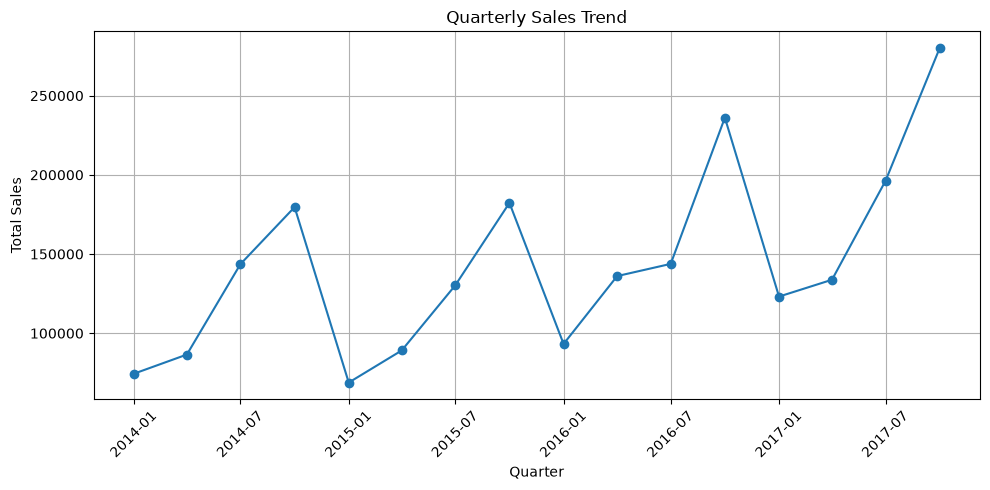

In [13]:
quarterly_sales = (
    df.dropna(subset=["Order Date"])
      .set_index("Order Date")["Sales"]
      .resample("QS")
      .sum()
)

plt.figure(figsize=(10, 5))
plt.plot(quarterly_sales.index, quarterly_sales.values, marker="o")
plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Observation: Quarterly Sales Trend

The quarterly sales chart summarizes sales performance over three-month periods. Comparing quarters helps identify periods of stronger or weaker demand and supports seasonal business planning.

## Customer Analysis

Customer analysis helps a business understand the types of customers represented in its orders. This dataset provides a Segment field with Consumer, Corporate, and Home Office categories. Counting records by segment shows how the dataset is distributed across these groups and can help guide segment-specific marketing or service planning.

The segment chart represents the distribution of records in the dataset, not necessarily the number of unique customers unless the code explicitly counts unique customer IDs. Customer demographics should only be analyzed when the relevant fields are available in the source data.

### Customer Demographics: Age and Gender

The selected Superstore dataset does not contain customer age or gender fields. Therefore, age-group and gender distributions cannot be calculated from the available data. Rather than generating misleading results, this analysis uses the available customer segment information as an alternative. A dataset containing age and gender would be required to complete those two demographic analyses.

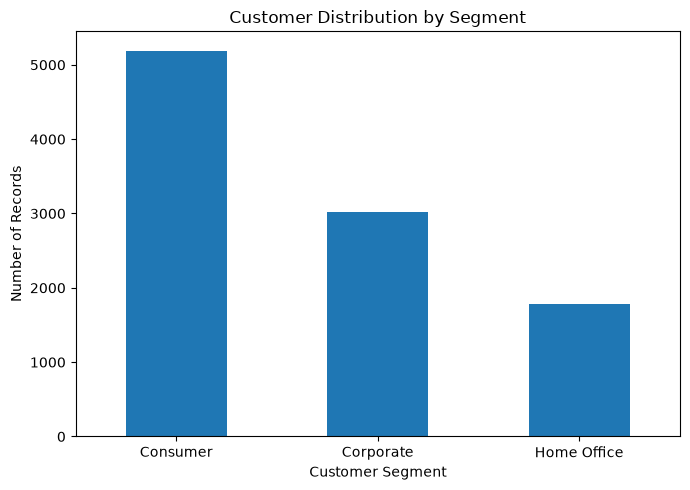

In [16]:
# Customer segment distribution
segment_counts = df["Segment"].value_counts()

plt.figure(figsize=(7, 5))
segment_counts.plot(kind="bar")
plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Customer Segment Distribution

The chart compares the available customer segments: Consumer, Corporate, and Home Office. The largest segment represents the biggest share of the analyzed records. This information can help the business tailor marketing and service strategies to different customer groups.

## Top 10 Best-Selling Products

Ranking products by total quantity sold highlights items that were ordered in the greatest quantities. Grouping records by product name and summing Quantity combines repeated orders for the same product. Sorting the totals from largest to smallest and selecting the first ten produces a concise list of high-volume products.

High quantity can signal strong demand and a need for careful inventory monitoring. However, the most frequently purchased products are not automatically the most profitable. Product decisions should also consider sales revenue, profit, discount levels, and stock costs.

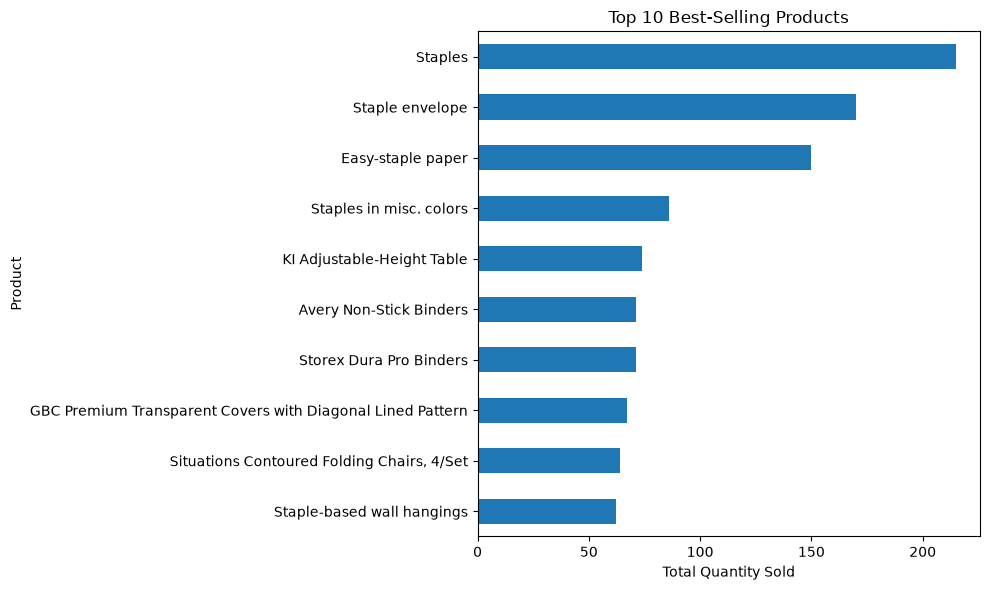

In [10]:
top_products = (
    df.groupby("Product Name")["Quantity"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

### Observation: Top 10 Best-Selling Products

The chart ranks products by total quantity sold. Products with higher quantities may require closer inventory monitoring to avoid stockouts. Sales quantity should also be considered alongside profit before deciding which products to prioritize.

## Revenue Analysis by Product Category

Product categories group related items into broad business areas. Summing Sales for each category allows their total sales revenue to be compared. A bar chart is effective because it makes differences between categories easy to see.

Revenue is the amount generated from sales, whereas profit reflects what remains after relevant costs. A category with high revenue may not have the highest profit. For this reason, category-level revenue should be interpreted together with profit and discount patterns before deciding where to invest marketing or inventory resources.

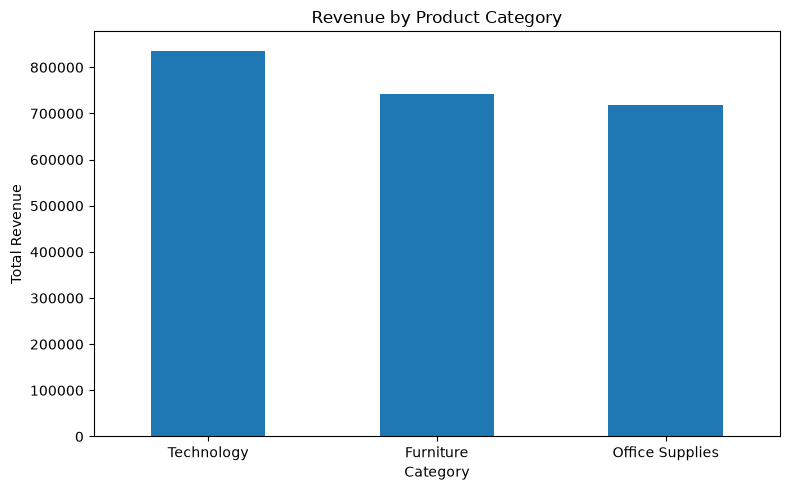

In [11]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values(
    ascending=False
)

plt.figure(figsize=(8, 5))
category_sales.plot(kind="bar")
plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Revenue by Product Category

The chart compares total sales revenue across product categories. The category with the highest revenue is the largest sales contributor, but revenue alone does not indicate profitability. Profit margins should also be considered when making business decisions.

## Correlation Matrix Heatmap

Correlation measures the strength and direction of a linear relationship between two numerical variables. The correlation coefficient usually ranges from -1 to +1: values near +1 indicate a strong positive relationship, values near -1 indicate a strong negative relationship, and values near 0 indicate little or no linear relationship.

A correlation matrix calculates these coefficients for each pair of selected numerical variables. A heatmap uses color and printed values to make the matrix easier to scan. The diagonal is 1.00 because each variable is perfectly correlated with itself. Correlation does not prove that one variable causes another, and a weak linear correlation does not rule out every possible relationship.

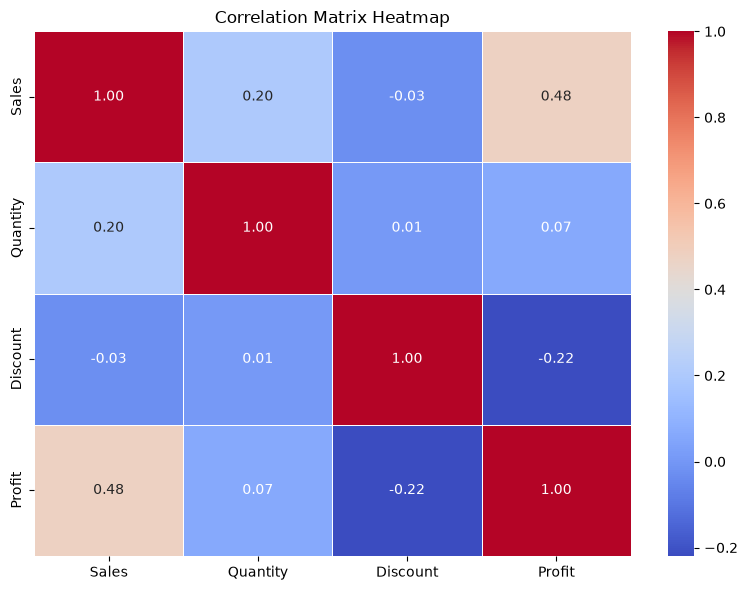

In [19]:

numeric_cols = ["Sales", "Quantity", "Discount", "Profit"]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix Heatmap")
plt.tight_layout()
plt.show()

### Observation: Correlation Matrix Heatmap

The heatmap displays the relationships between numerical variables such as Sales, Quantity, Discount, and Profit. Correlation values closer to +1 indicate stronger positive relationships, values closer to -1 indicate stronger negative relationships, and values near 0 indicate weaker linear relationships. Correlation does not establish causation.

## Additional Business Insight: Profit by Region

Regional analysis compares business performance across geographic areas. Summing Profit for each region gives the total recorded profit contribution of each region and can reveal differences that merit further investigation.

A region with lower total profit is not necessarily performing poorly in every respect; its sales volume, customer mix, discounts, and operating costs may differ. The chart is a starting point for asking follow-up questions rather than proof of a single cause. Reviewing both sales and profit provides a more balanced view of regional performance.

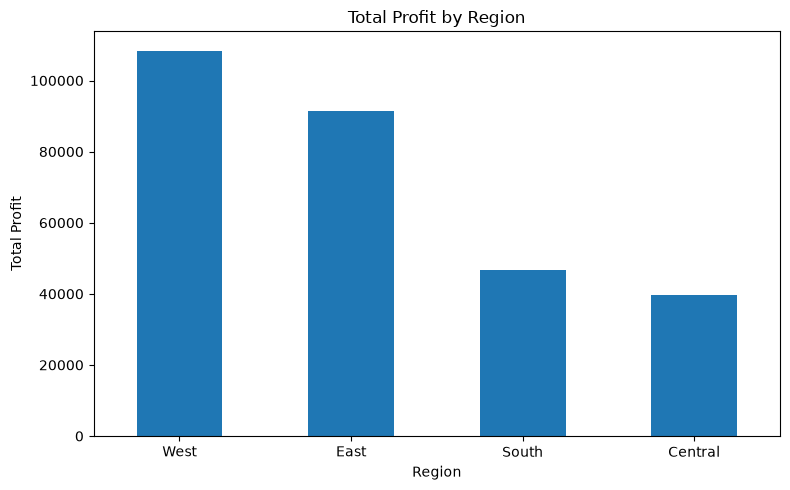

In [18]:
region_profit = (
    df.groupby("Region")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
region_profit.plot(kind="bar")
plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Observation: Total Profit by Region

This chart compares the total profit generated by each region. Regions with higher profits contribute more to overall profitability, while regions with lower or negative profits may require further investigation. The business should examine product mix, discounts, and sales performance before deciding on corrective actions.

## Conclusion and Business Recommendations

Exploratory Data Analysis provides a structured overview of the retail dataset by combining data inspection, numerical summaries, time-based aggregation, customer-segment analysis, product rankings, category comparisons, correlation analysis, and regional profit analysis. The results should be interpreted as descriptions of the available historical data, not as proof of cause-and-effect relationships.

The analysis can support business decisions by identifying periods of changing demand, high-volume products, major sales categories, and differences in regional profit. Before acting on any finding, the business should consider additional context such as costs, inventory levels, promotions, and market conditions.

## Business Recommendations

1. Improve inventory planning: Use monthly and quarterly sales patterns to anticipate demand and maintain adequate stock of high-volume products.
2. Focus on profitable products: Evaluate quantity, revenue, and profit together when deciding which products to promote or prioritize.
3. Review regional performance: Investigate regions with comparatively low profits by examining sales, product mix, discounts, and costs.
4. Evaluate discount strategies: Study discount levels alongside profit to identify patterns that may indicate reduced profitability.
5. Tailor marketing by segment: Use the available Consumer, Corporate, and Home Office segments to develop relevant offers.
   
## Limitations and Future Improvements

The selected dataset does not include customer age or gender, so those demographic distributions cannot be calculated from this file. Further analysis could include customer-level measures, profit margins, shipping time, discount effects, and additional external information if suitable data becomes available. Any new conclusions should be checked against the actual data and business context.